Q:1


Enter a value for M: 8


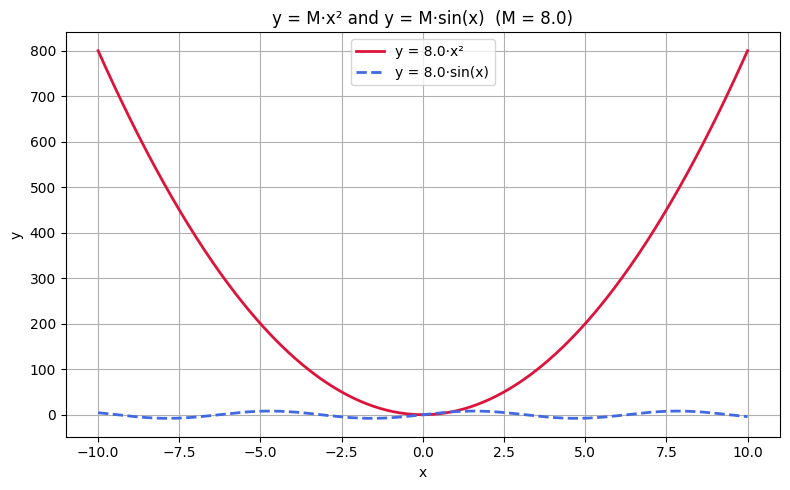

In [3]:
import numpy as np
import matplotlib.pyplot as plt

M = float(input("Enter a value for M: "))

x = np.linspace(-10, 10, 400)
y1 = M * x ** 2
y2 = M * np.sin(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y1, color="crimson", linestyle="-", linewidth=2, label=f"y = {M}·x²")
plt.plot(x, y2, color="royalblue", linestyle="--", linewidth=2, label=f"y = {M}·sin(x)")
plt.title(f"y = M·x² and y = M·sin(x)  (M = {M})")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

            Subject  Score
0             Maths     88
1           Physics     76
2         Chemistry     69
3           English     82
4  Computer Science     94


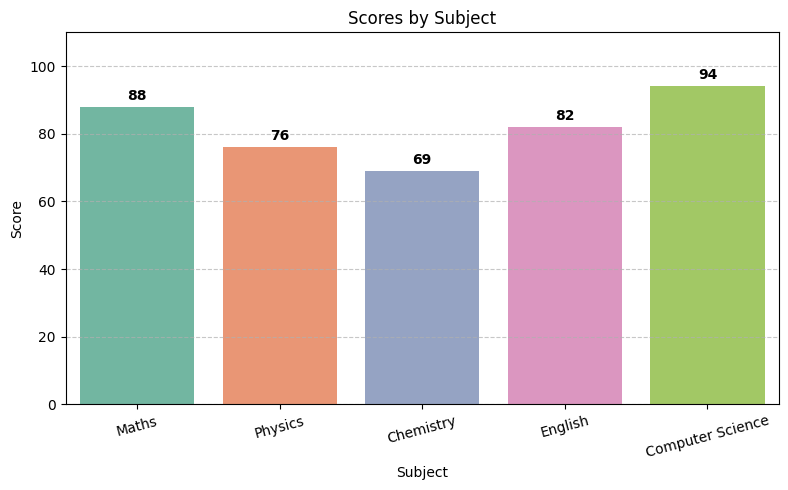

In [4]:
# Q2: Seaborn bar plot of five subjects and scores
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

data = {
    "Subject": ["Maths", "Physics", "Chemistry", "English", "Computer Science"],
    "Score": [88, 76, 69, 82, 94],
}
df = pd.DataFrame(data)
print(df)

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=df, x="Subject", y="Score", hue="Subject",
                 palette="Set2", legend=False)   # different color per bar

for container in ax.containers:                  # value on top of each bar
    ax.bar_label(container, fmt="%d", padding=3, fontweight="bold")

ax.set_title("Scores by Subject")
ax.set_xlabel("Subject")
ax.set_ylabel("Score")
ax.set_ylim(0, 110)
ax.grid(True, axis="y", linestyle="--", alpha=0.7)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

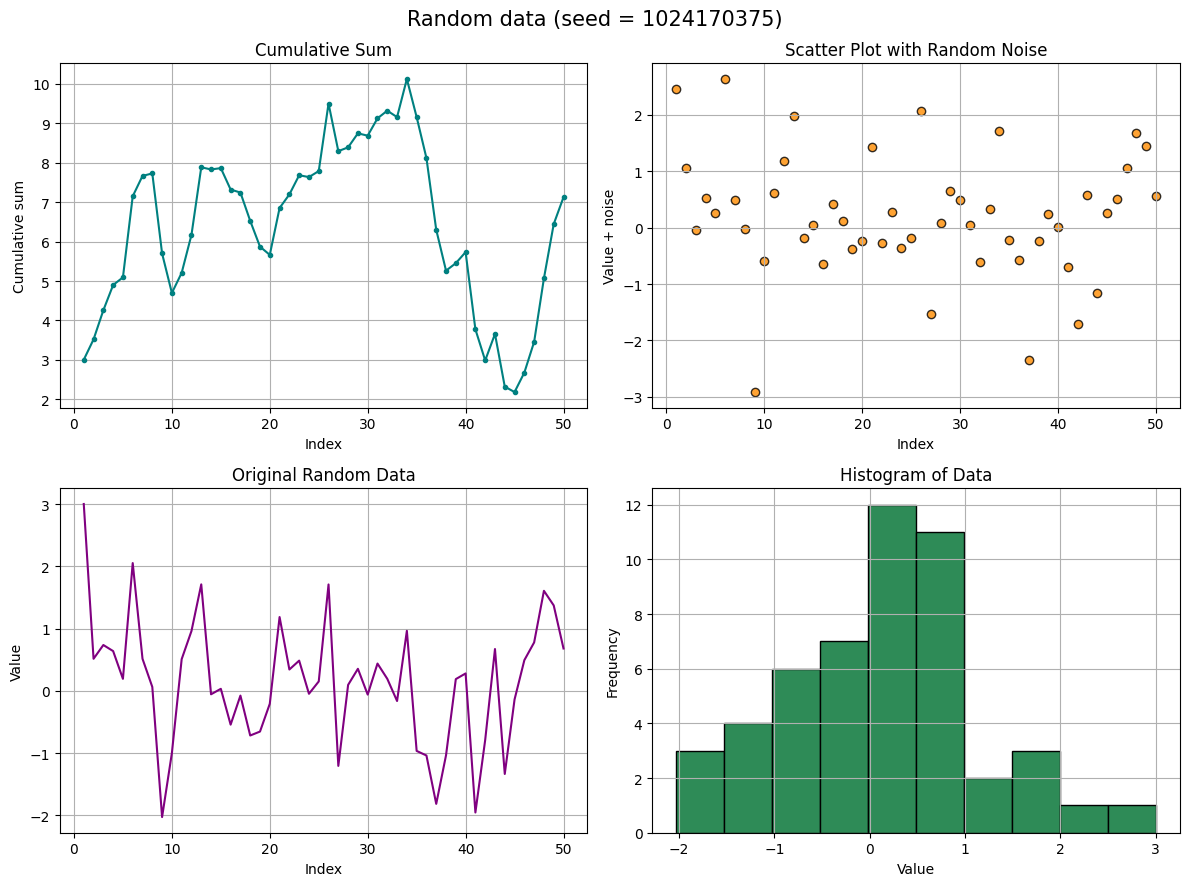

In [5]:
# Q3: Seeded random data and 2x2 subplots
import numpy as np
import matplotlib.pyplot as plt

ROLL_NO = 1024170375
np.random.seed(ROLL_NO)

data = np.random.randn(50)
idx = np.arange(1, 51)
cumulative = np.cumsum(data)
noisy = data + 0.5 * np.random.randn(50)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle(f"Random data (seed = {ROLL_NO})", fontsize=15)

axes[0, 0].plot(idx, cumulative, color="teal", marker="o", markersize=3)
axes[0, 0].set_title("Cumulative Sum")
axes[0, 0].set_xlabel("Index")
axes[0, 0].set_ylabel("Cumulative sum")
axes[0, 0].grid(True)

axes[0, 1].scatter(idx, noisy, color="darkorange", alpha=0.8, edgecolor="k")
axes[0, 1].set_title("Scatter Plot with Random Noise")
axes[0, 1].set_xlabel("Index")
axes[0, 1].set_ylabel("Value + noise")
axes[0, 1].grid(True)

axes[1, 0].plot(idx, data, color="purple")
axes[1, 0].set_title("Original Random Data")
axes[1, 0].set_xlabel("Index")
axes[1, 0].set_ylabel("Value")
axes[1, 0].grid(True)

axes[1, 1].hist(data, bins=10, color="seagreen", edgecolor="black")
axes[1, 1].set_title("Histogram of Data")
axes[1, 1].set_xlabel("Value")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

Saving company_sales_data.csv to company_sales_data.csv
   month_number  facecream  facewash  toothpaste  bathingsoap  shampoo  \
0             1       2500      1500        5200         9200     1200   
1             2       2630      1200        5100         6100     2100   
2             3       2140      1340        4550         9550     3550   
3             4       3400      1130        5870         8870     1870   
4             5       3600      1740        4560         7760     1560   

   moisturizer  total_units  total_profit  
0         1500        21100        211000  
1         1200        18330        183300  
2         1340        22470        224700  
3         1130        22270        222700  
4         1740        20960        209600  


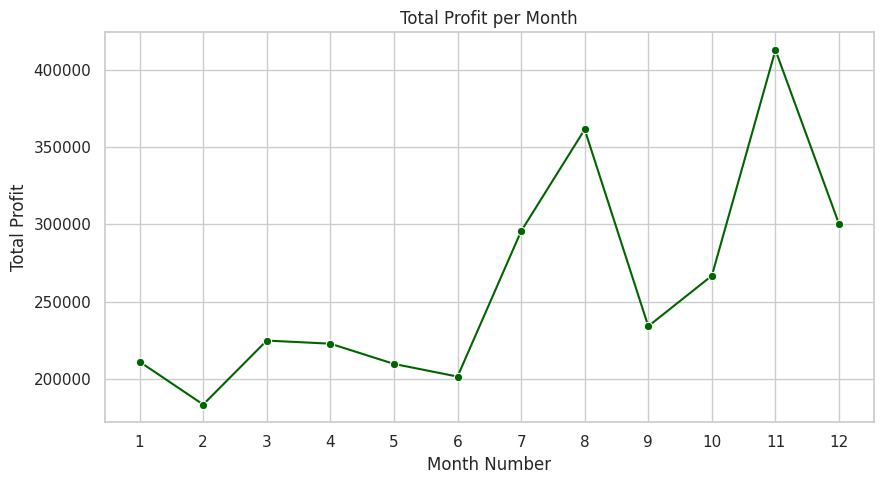

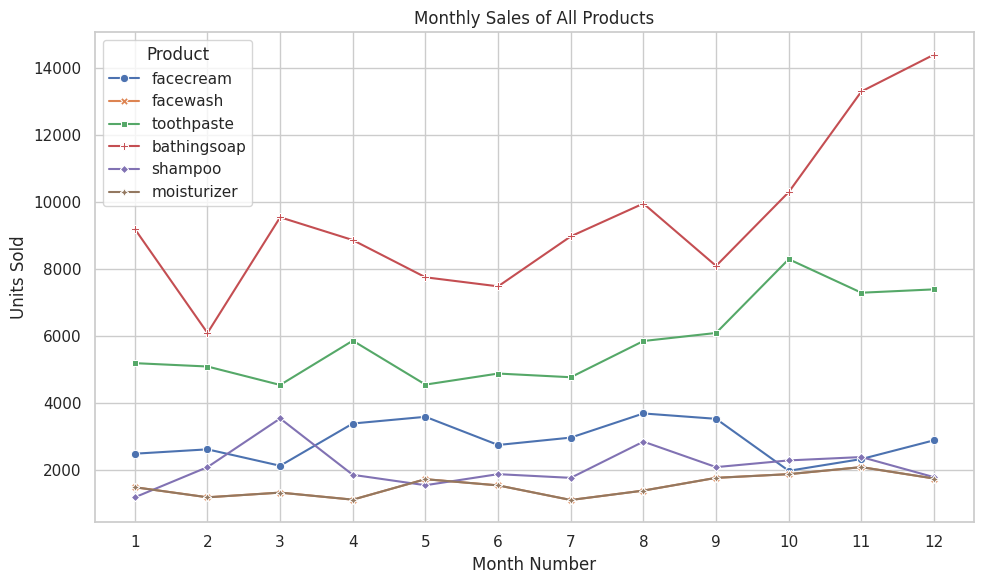

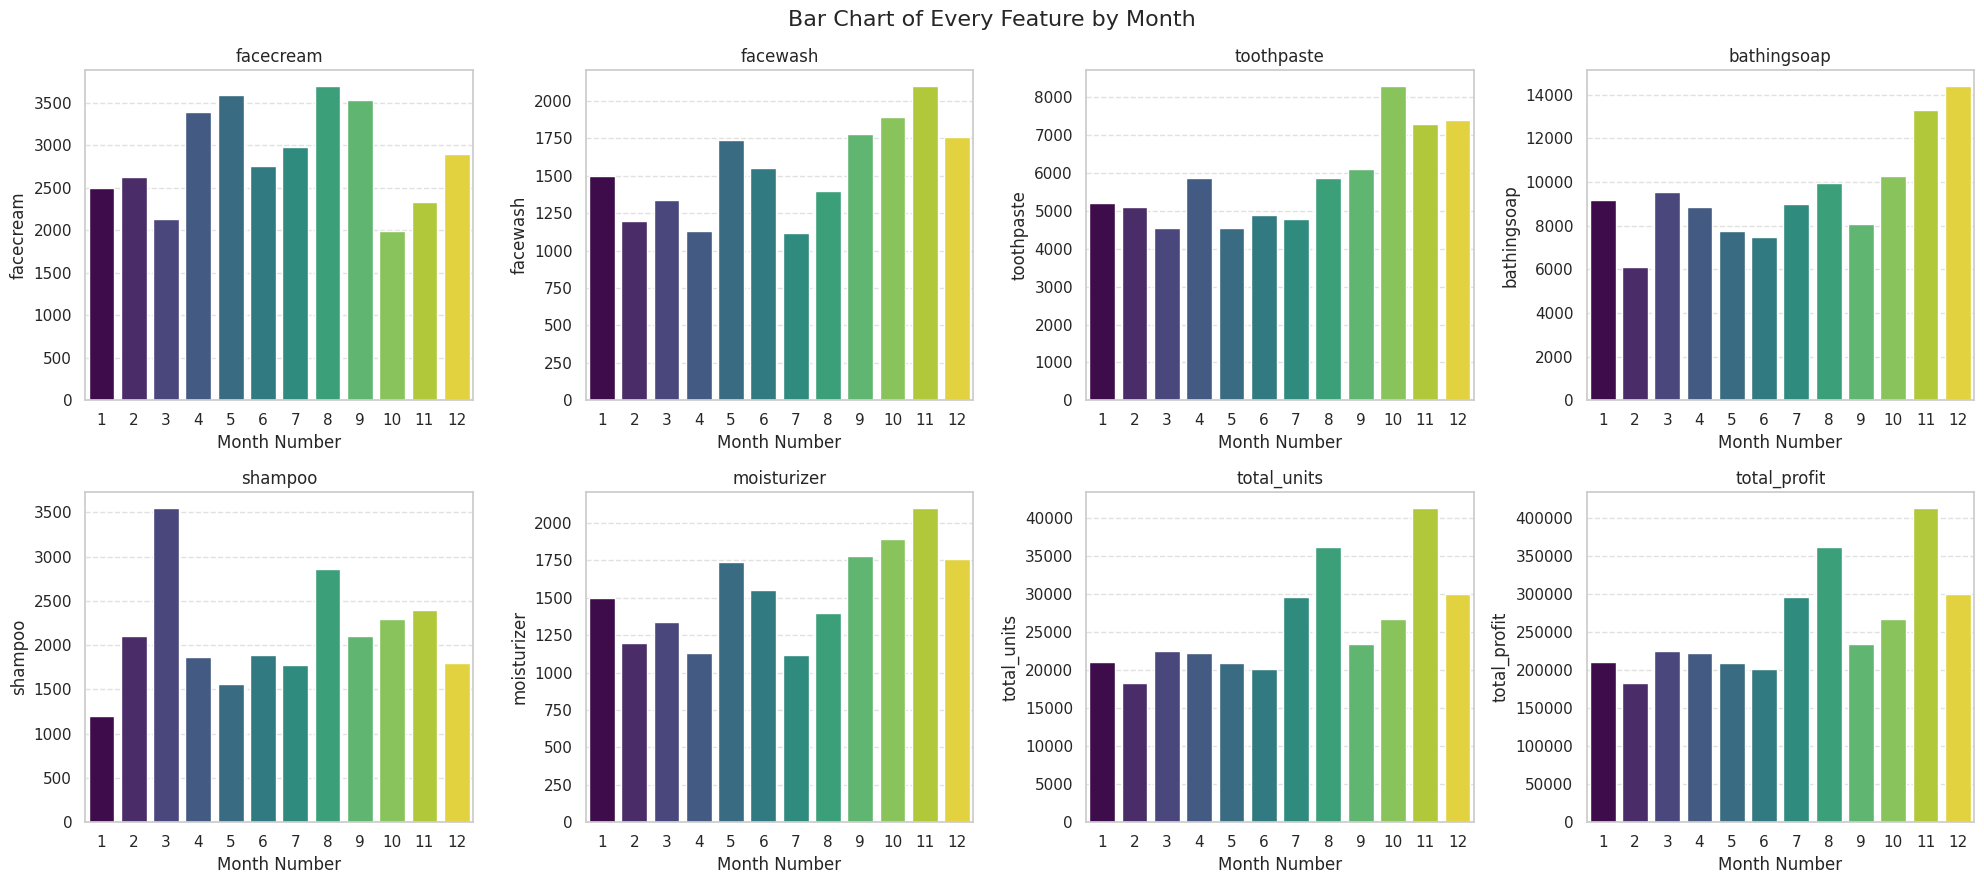

In [7]:
# Q4: company_sales_data.csv with Seaborn - choose/upload the CSV from your PC
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


def get_csv_path():
    # Google Colab: opens an upload button
    try:
        from google.colab import files
        uploaded = files.upload()
        return list(uploaded.keys())[0]
    except ImportError:
        pass
    # Normal PC (VS Code / IDLE / terminal): opens a file-picker window
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)
        path = filedialog.askopenfilename(
            title="Select company_sales_data.csv",
            filetypes=[("CSV files", "*.csv")])
        root.destroy()
        if path:
            return path
    except Exception:
        pass
    # Last fallback: type the path
    return input("Enter full path of the CSV file: ").strip().strip('"')


sns.set_theme(style="whitegrid")
df = pd.read_csv(get_csv_path())
print(df.head())

# 1. Total profit of all months - line plot
plt.figure(figsize=(9, 5))
sns.lineplot(data=df, x="month_number", y="total_profit", marker="o", color="darkgreen")
plt.title("Total Profit per Month")
plt.xlabel("Month Number")
plt.ylabel("Total Profit")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. All product sales - multiline plot
products = ["facecream", "facewash", "toothpaste", "bathingsoap", "shampoo", "moisturizer"]
long_df = df.melt(id_vars="month_number", value_vars=products,
                  var_name="Product", value_name="Units Sold")
plt.figure(figsize=(10, 6))
sns.lineplot(data=long_df, x="month_number", y="Units Sold",
             hue="Product", style="Product", markers=True, dashes=False)
plt.title("Monthly Sales of All Products")
plt.xlabel("Month Number")
plt.ylabel("Units Sold")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Bar chart for all features/attributes (each column vs month)
features = [c for c in df.columns if c != "month_number"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flatten(), features):
    sns.barplot(data=df, x="month_number", y=col, hue="month_number",
                palette="viridis", legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Month Number")
    ax.set_ylabel(col)
    ax.grid(True, axis="y", linestyle="--", alpha=0.6)
fig.suptitle("Bar Chart of Every Feature by Month", fontsize=16)
plt.tight_layout()
plt.show()